# Plan-and-execute: do more workers help?
*Agentic AI Systems · symbolic regression notebook*

Each round, the orchestrator plans *k* directions; each worker turns one direction into **one equation**; the
results go back to the orchestrator. A round costs *k* evaluations.

1. **Speedup:** do *k* workers converge *k* times faster?
2. **Task distribution:** do the workers explore different options?
   Ablation (`diverse`): the orchestrator is told to give every worker a different kind of direction.

**Orchestrator prompt** (neutral):

> You lead a research team discovering the equation behind the data.
> You do not write equations yourself. Each round you call submit_plan with k research
> direction(s), one per worker. Each worker proposes one equation for its direction, and
> the harness evaluates it on the training data. Use the results of earlier rounds to plan
> the next one. If you are confident that no better equation can be found, call finish
> instead of submit_plan.

**`diverse`** adds one sentence:

> Give every worker a different kind of direction (for example: polynomial,
> trigonometric, exponential or logarithmic, rational), so that the team explores
> different options in parallel.

**Setup:** *k* = 1, 2, 4 workers; 32 evaluations for every *k* (32, 16 and 8 rounds).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from sr_harness import load_config
from sr_harness.analysis import multi_agent as MA
from sr_harness.analysis import plots
from sr_harness.benchmark import load_tasks
from sr_harness.benchmark.loader import load_llm_srbench
from sr_harness.experiments.runner import run_grid
from sr_harness.llm import LLMClient

LIVE = False        # False: replay the recorded runs; True: run the experiment (OpenRouter + HF login)
ROOT = "runs" if LIVE else "recorded"
OUT = f"{ROOT}/multi_agent"
K = [1, 2, 4]
NEUTRAL = {k: f"plan_execute_k{k}" for k in K}
DIVERSE = {k: f"plan_execute_k{k}_diverse" for k in (2, 4)}
HARNESSES = list(NEUTRAL.values()) + list(DIVERSE.values())
N_TASKS, SEEDS, BUDGET = 40, [0, 1, 2, 3], 32

cfg = load_config()
cfg["benchmark"]["n_tasks"] = N_TASKS
cfg["experiment"]["budget"].update(max_evaluations=BUDGET, max_model_calls=200)
print("model:", cfg["model"]["model"])


model: openai/gpt-oss-20b


## 1. Run the experiment (or load the recorded runs)
40 tasks × 4 seeds × 5 harnesses = 800 runs.

In [2]:
if LIVE:
    tasks = load_tasks(cfg["benchmark"])
    make_llm = lambda logger, seed: LLMClient(cfg["model"], logger=logger, seed=seed)
    run_grid(tasks, HARNESSES, SEEDS, cfg, make_llm, OUT)

results = [r for r in plots.load_results(OUT) if r["harness"] in HARNESSES]
print(len(results), "runs:", pd.Series([r["harness"] for r in results]).value_counts().sort_index().to_dict())

800 runs: {'plan_execute_k1': 160, 'plan_execute_k2': 160, 'plan_execute_k2_diverse': 160, 'plan_execute_k4': 160, 'plan_execute_k4_diverse': 160}


## 2. Speedup: do *k* workers converge *k* times faster?
Score after each round of the best equation so far. Dashed: `diverse`. Bands: 95% CI over tasks.

**Ideal (dotted):** the one-worker curve at round *k·r*: same number of experiments, *k* times fewer rounds.
Below it, parallel workers waste experiments; above it, parallel beats sequential.

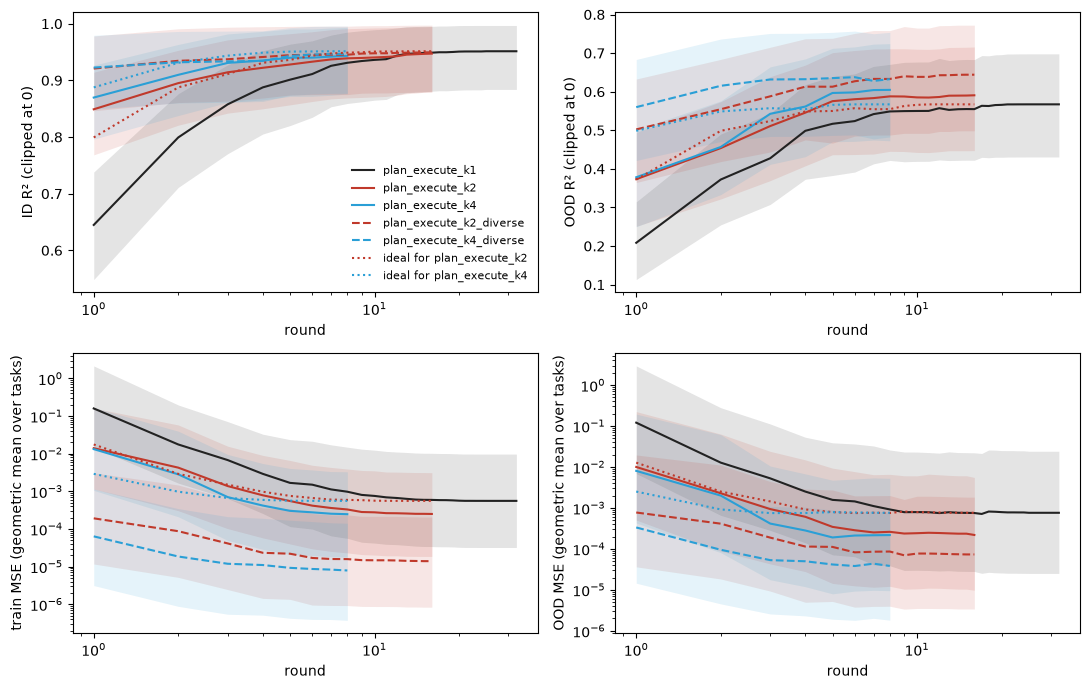

In [3]:
last_round = {NEUTRAL[k]: BUDGET // k for k in K} | {DIVERSE[k]: BUDGET // k for k in DIVERSE}
ideal = (NEUTRAL[1], {NEUTRAL[k]: k for k in K if k > 1})
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, metric in zip(axes.flat, ["train_dist_r2", "ood_r2", "train_mse", "ood_mse"]):
    MA.plot_vs_rounds(results, OUT, metric, last_round, ideal=ideal, ax=ax)
for ax in list(axes.flat)[1:]:
    ax.get_legend().remove()
fig.tight_layout()
plt.show()

### R² vs. tokens
The same runs against compute: tokens of all model calls (orchestrator and workers).

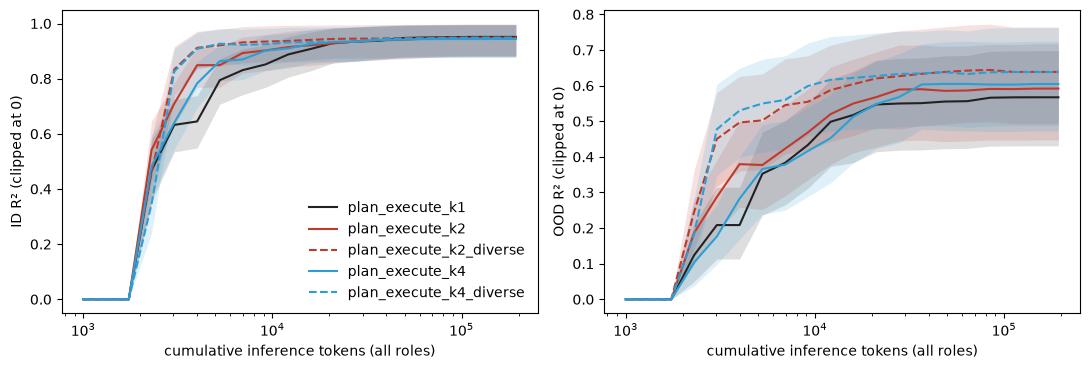

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
plots.plot_vs_tokens(results, metric="train_dist_r2", ax=axes[0])
plots.plot_vs_tokens(results, metric="ood_r2", ax=axes[1])
axes[1].get_legend().remove()
fig.tight_layout()
plt.show()

## 3. Task distribution: do workers explore different options?
Three ways two workers in the same round can overlap, from loose to strict:

| Overlap | Two workers' equations… | Example |
|---|---|---|
| **same family** | use the same kind of functions (polynomial, trig, exp/log, rational) | `c0*x + c1` and `c0*t**3` |
| **same predictions** | give the same predictions on the training inputs (within 0.1%) | `c0*x` and `c0*x + c1*t` with `c1` ≈ 0 |
| **same equation** | are identical up to the order of terms and the names of constants | `c0*x + c1` and `c3 + c2*x` |

Table: fraction of rounds with at least one overlapping pair of workers (per task, then over tasks).

In [5]:
if LIVE:   # "same predictions" needs the training inputs; the recorded runs ship the table instead
    all_tasks = {t.task_id: t for t in load_llm_srbench(cfg["benchmark"]["subsets"], cfg["benchmark"]["data_dir"])}
    div = MA.diversity_table(results, OUT, all_tasks)
else:
    div = pd.read_csv(f"{OUT}/overlap.csv")
div["same family"] = div["families"] < div["workers"]
div["same predictions"] = div["equivalent_pairs"] > 0
div["same equation"] = div["same_form"]
order = [NEUTRAL[2], DIVERSE[2], NEUTRAL[4], DIVERSE[4]]
cols = ["same family", "same predictions", "same equation"]
per_task = div.groupby(["harness", "task"])[cols].mean()          # per task, then over tasks
per_task.groupby("harness").mean().loc[[h for h in order if h in set(div.harness)]].map(lambda v: f"{v:.0%}")

,same family,same predictions,same equation
harness,,,
plan_execute_k2,61%,12%,1%
plan_execute_k2_diverse,12%,4%,0%
plan_execute_k4,95%,30%,5%
plan_execute_k4_diverse,57%,20%,3%


## 4. A trace: the diverse orchestrator, *k* = 4
Seed 0, on the task where `diverse` and neutral differ most (chosen on purpose, not a typical task). Each round: the
direction each worker got, the equation it proposed, its train R² and family.

In [6]:
import json

def run(h, task, seed=0):
    return next(r for r in results if r["harness"] == h and r["task_id"] == task and r["seed"] == seed)

def r2(r, split):
    return max(0.0, r["scores"][split]["r2"]) if r["scores"][split] else 0.0

def show_trace(h, task, seed=0):
    r = run(h, task, seed)
    log = MA.log_path(OUT, r)
    stop = next((e for e in map(json.loads, open(log)) if e["event"] == "stop"), None)
    print(f"===== {h}   (ID R² = {r2(r, 'train_dist'):.3f}, OOD R² = {r2(r, 'ood'):.3f}, "
          f"{r['evaluations']} evaluations)")
    for rd in MA.rounds(log):
        print(f"round {rd['round']}")
        for w in rd["workers"]:
            e = w["evaluations"][0] if w["evaluations"] else None
            score = f"train R² {e['train_r2']:.3f}, {MA.family(e['expression'])}" if e and e["error"] is None else "error"
            print(f"  worker {w['worker']}: {w['direction'][:100]}")
            print(f"        -> {e['expression'][:90] if e else '-'}   ({score})")
    print("stopped:", "budget used" if stop is None else f"{stop['role']} called finish" if stop["reason"] != "no tool call"
          else "no tool call")

pairs = {(r["task_id"]) for r in results if r["harness"] == NEUTRAL[4] and r["seed"] == 0} &         {(r["task_id"]) for r in results if r["harness"] == DIVERSE[4] and r["seed"] == 0}
task = max(sorted(pairs), key=lambda t: abs(r2(run(DIVERSE[4], t), "train_dist") - r2(run(NEUTRAL[4], t), "train_dist")))
print("task:", task, "\n")
show_trace(DIVERSE[4], task)

task: phys_osc/PO24 

===== plan_execute_k4_diverse   (ID R² = 0.986, OOD R² = 0.994, 24 evaluations)
round 1
  worker 0: c0 + c1*t + c2*v + c3*t**2 + c4*t*v + c5*v**2 + c6*t**3 + c7*v**3
        -> c0 + c1*t + c2*v + c3*t**2 + c4*t*v + c5*v**2 + c6*t**3 + c7*v**3   (train R² 0.177, polynomial)
  worker 1: c0*sin(c1*t)+c2*cos(c3*v)+c4*t*v
        -> c0*sin(c1*t)+c2*cos(c3*v)+c4*t*v   (train R² 0.791, trig)
  worker 2: c0*exp(c1*t)*v + c2*t + c3
        -> c0*exp(c1*t)*v + c2*t + c3   (train R² 0.115, exp/log)
  worker 3: c0*t/(c1+v)+c2*v**2+c3
        -> c0*t/(c1+v)+c2*v**2+c3   (train R² 0.035, rational)
round 2
  worker 0: c0*sin(c1*t)+c2*cos(c3*v)+c4*t*v + c5*v**2 + c6*t**2
        -> c0*sin(c1*t)+c2*cos(c3*v)+c4*t*v + c5*v**2 + c6*t**2   (train R² 0.876, trig)
round 3
  worker 0: c0*sin(c1*t)*v + c2*cos(c3*v)*t + c4*v**2 + c5*t**2
        -> c0*sin(c1*t)*v + c2*cos(c3*v)*t + c4*v**2 + c5*t**2   (train R² 0.665, trig)
round 4
  worker 0: c0*t**2 + c1*v**2 + c2*t*v + c3*sin(c4*t)*v +